In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
sys.path.append("../src")

In [3]:
from Bio import Phylo
import networkx as nx

tree = Phylo.read("../data/laml/problin_1461.nwk", "newick")

G = Phylo.to_networkx(tree)

print(G.number_of_nodes())
print(G.number_of_edges())

2921
2920


In [4]:
# from collections import defaultdict
# from pathlib import Path

# import convexml
# import pandas as pd

# problin_tree_path = Path("../data/laml/problin_1461.nwk")
# allele_table_path = Path("../data/KPTracer-Data/KPTracer.alleleTable.FINAL.txt")
# convexml_output_path = Path("../data/laml/problin_1461_convexml_timed.nwk")

# problin_tree_newick = problin_tree_path.read_text().strip()
# problin_tree = Phylo.read(str(problin_tree_path), "newick")
# problin_leaf_names = [leaf.name for leaf in problin_tree.get_terminals()]

# allele_table = pd.read_csv(
#     allele_table_path,
#     sep="\t",
#     usecols=["cellBC", "intBC", "r1", "r2", "r3"],
#     dtype=str,
# )
# allele_table = allele_table[allele_table["cellBC"].isin(problin_leaf_names)]
# if allele_table.duplicated(["cellBC", "intBC"]).any():
#     raise ValueError("Expected at most one allele-table row per cell and intBC")

# cut_sites = ["r1", "r2", "r3"]
# features = sorted(
#     {
#         (row.intBC, cut_site)
#         for row in allele_table.itertuples(index=False)
#         for cut_site in cut_sites
#     }
# )
# feature_indices = {feature: index for index, feature in enumerate(features)}
# alleles_by_feature = defaultdict(set)
# for row in allele_table.itertuples(index=False):
#     for cut_site in cut_sites:
#         allele = getattr(row, cut_site)
#         if pd.notna(allele):
#             alleles_by_feature[(row.intBC, cut_site)].add(allele)

# state_codes = {}
# for feature in features:
#     feature_alleles = alleles_by_feature[feature]
#     unedited_alleles = sorted(
#         allele for allele in feature_alleles if "[None]" in allele
#     )
#     edited_alleles = sorted(
#         allele for allele in feature_alleles if "[None]" not in allele
#     )
#     state_codes[feature] = {allele: 0 for allele in unedited_alleles}
#     state_codes[feature].update(
#         {allele: state for state, allele in enumerate(edited_alleles, start=1)}
#     )

# leaf_sequences = {
#     leaf_name: [-1] * len(features) for leaf_name in problin_leaf_names
# }
# for row in allele_table.itertuples(index=False):
#     for cut_site in cut_sites:
#         allele = getattr(row, cut_site)
#         if pd.notna(allele):
#             feature = (row.intBC, cut_site)
#             leaf_sequences[row.cellBC][feature_indices[feature]] = state_codes[feature][allele]

# sequence_lengths = {len(sequence) for sequence in leaf_sequences.values()}
# if len(sequence_lengths) != 1 or set(leaf_sequences) != set(problin_leaf_names):
#     raise ValueError("ConvexML sequences do not match the Problin tree leaves")

# minimum_branch_length = min(0.01, 0.5 / (2 * len(problin_leaf_names) - 2))
# print(
#     f"Prepared {len(leaf_sequences)} leaves with {len(features)} allele features; "
#     f"{len(problin_leaf_names) - allele_table['cellBC'].nunique()} leaves have no allele records."
# )
# print("Using minimum branch length", minimum_branch_length)

# convexml_result = convexml.convexml(
#     tree_newick=problin_tree_newick,
#     leaf_sequences=leaf_sequences,
#     ancestral_state_reconstructor="conservative_maximum_parsimony",
#     resolve_multifurcations_before_branch_length_estimation=True,
#     recover_multifurcations_after_branch_length_estimation=False,
#     minimum_branch_length=minimum_branch_length,
#     pseudo_mutations_per_edge=0.05,
#     pseudo_non_mutations_per_edge=0.05,
#     solver="ECOS",
#     backup_solver="SCS",
#     verbose=True,
# )

# convexml_output_path.write_text(convexml_result["tree_newick"] + "\n")
# print("Saved ConvexML timed tree to", convexml_output_path)


In [5]:
print(G.edges(data=True))
print(G.nodes(data=True))

[(Clade(branch_length=0.005), Clade(branch_length=0.19311067051961742), {'weight': 0.19311067051961742}), (Clade(branch_length=0.005), Clade(branch_length=0.005), {'weight': 0.005}), (Clade(branch_length=0.19311067051961742), Clade(branch_length=0.46475513319561146), {'weight': 0.46475513319561146}), (Clade(branch_length=0.19311067051961742), Clade(branch_length=2.282915814433405, name='L8.CGGAGCTTCGGAAATA-1'), {'weight': 2.282915814433405}), (Clade(branch_length=0.46475513319561146), Clade(branch_length=0.3843457381117571), {'weight': 0.3843457381117571}), (Clade(branch_length=0.46475513319561146), Clade(branch_length=1.818160681237794, name='L9.CTGCGGAGTAGGCTGA-1'), {'weight': 1.818160681237794}), (Clade(branch_length=0.3843457381117571), Clade(branch_length=1.4338149431260367, name='L9.GAACATCTCTCTAGGA-1'), {'weight': 1.4338149431260367}), (Clade(branch_length=0.3843457381117571), Clade(branch_length=0.912487875305582), {'weight': 0.912487875305582}), (Clade(branch_length=0.91248787

In [6]:
G.nodes

NodeView((Clade(branch_length=0.005), Clade(branch_length=0.19311067051961742), Clade(branch_length=0.46475513319561146), Clade(branch_length=0.3843457381117571), Clade(branch_length=1.4338149431260367, name='L9.GAACATCTCTCTAGGA-1'), Clade(branch_length=0.912487875305582), Clade(branch_length=0.0050035271521436), Clade(branch_length=0.005000661274110419), Clade(branch_length=0.5113228749087244, name='L11.CGAGCACGTACCGAGA-1'), Clade(branch_length=0.5113228749087244, name='L8.CAAGAAAGTCGCGGTT-1'), Clade(branch_length=0.5163235361828349, name='L8.GTCAAGTGTTCCACAA-1'), Clade(branch_length=0.5213270633349785, name='L11.TAGTGGTTCATACGGT-1'), Clade(branch_length=1.818160681237794, name='L9.CTGCGGAGTAGGCTGA-1'), Clade(branch_length=2.282915814433405, name='L8.CGGAGCTTCGGAAATA-1'), Clade(branch_length=0.005), Clade(branch_length=0.7878975489609431), Clade(branch_length=0.5970955952415664), Clade(branch_length=1.0860340747123287, name='L8.TCGAGGCGTATAAACG-1'), Clade(branch_length=1.0860340747123

In [7]:
for u, v, d in G.edges(data=True):
    print(u, v, d)

Clade Clade {'weight': 0.19311067051961742}
Clade Clade {'weight': 0.005}
Clade Clade {'weight': 0.46475513319561146}
Clade L8.CGGAGCTTCGGAAATA-1 {'weight': 2.282915814433405}
Clade Clade {'weight': 0.3843457381117571}
Clade L9.CTGCGGAGTAGGCTGA-1 {'weight': 1.818160681237794}
Clade L9.GAACATCTCTCTAGGA-1 {'weight': 1.4338149431260367}
Clade Clade {'weight': 0.912487875305582}
Clade Clade {'weight': 0.0050035271521436}
Clade L11.TAGTGGTTCATACGGT-1 {'weight': 0.5213270633349785}
Clade Clade {'weight': 0.005000661274110419}
Clade L8.GTCAAGTGTTCCACAA-1 {'weight': 0.5163235361828349}
Clade L11.CGAGCACGTACCGAGA-1 {'weight': 0.5113228749087244}
Clade L8.CAAGAAAGTCGCGGTT-1 {'weight': 0.5113228749087244}
Clade Clade {'weight': 0.7878975489609431}
Clade Clade {'weight': 0.005}
Clade Clade {'weight': 0.5970955952415664}
Clade L8.TCACGAATCCCATTAT-1 {'weight': 1.6831296699538951}
Clade L8.TCGAGGCGTATAAACG-1 {'weight': 1.0860340747123287}
Clade L8.GCTCCTAGTTCGTGAT-1 {'weight': 1.0860340747123287}
Cla

In [8]:
for n, d in G.nodes(data=True):
    print(n, d)

Clade {}
Clade {}
Clade {}
Clade {}
L9.GAACATCTCTCTAGGA-1 {}
Clade {}
Clade {}
Clade {}
L11.CGAGCACGTACCGAGA-1 {}
L8.CAAGAAAGTCGCGGTT-1 {}
L8.GTCAAGTGTTCCACAA-1 {}
L11.TAGTGGTTCATACGGT-1 {}
L9.CTGCGGAGTAGGCTGA-1 {}
L8.CGGAGCTTCGGAAATA-1 {}
Clade {}
Clade {}
Clade {}
L8.TCGAGGCGTATAAACG-1 {}
L8.GCTCCTAGTTCGTGAT-1 {}
L8.TCACGAATCCCATTAT-1 {}
Clade {}
Clade {}
Clade {}
Clade {}
Clade {}
Clade {}
L9.GGGCACTAGTAACCCT-1 {}
L9.ACCTTTAGTCAAACTC-1 {}
L10.GTGCATAGTTATCCGA-1 {}
L8.CCGTACTCAGCTGCTG-1 {}
Clade {}
Clade {}
Clade {}
L9.TTTATGCTCCAGTATG-1 {}
Clade {}
Clade {}
Clade {}
Clade {}
Clade {}
L10.TGCCCATGTAGCGCTC-1 {}
Clade {}
L10.ATTGGTGGTTCGCTAA-1 {}
L10.CATCCACAGAAACGAG-1 {}
Clade {}
Clade {}
L10.TGATTTCGTCGCTTCT-1 {}
L10.GGGCACTTCTTACCTA-1 {}
L10.CACAGTAAGATGGCGT-1 {}
Clade {}
Clade {}
Clade {}
Clade {}
Clade {}
Clade {}
L9.TCGTACCGTCAACATC-1 {}
L10.GAAATGACACGGCTAC-1 {}
Clade {}
Clade {}
Clade {}
Clade {}
Clade {}
L9.CAGCGACTCCTATTCA-1 {}
L10.TCGTAGAGTTGTTTGG-1 {}
L9.GGCTCGACAGCATGAG-1 

In [9]:
mapping = {
    node: i
    for i, node in enumerate(G.nodes())
}

G = nx.relabel_nodes(G, mapping)

In [10]:
for u, v in G.edges():
    G.edges[u, v]['length'] = G.edges[u, v]['weight']

In [11]:
root = tree.root

DG = nx.DiGraph()

for parent in tree.find_clades(order="level"):
    for child in parent.clades:
        DG.add_edge(parent, child, length=child.branch_length)

In [12]:
for n, d in DG.nodes(data=True):
    print(n, d)

Clade {}
Clade {}
Clade {}
Clade {}
L8.CGGAGCTTCGGAAATA-1 {}
Clade {}
Clade {}
Clade {}
L9.CTGCGGAGTAGGCTGA-1 {}
Clade {}
L8.TCACGAATCCCATTAT-1 {}
Clade {}
Clade {}
L9.GAACATCTCTCTAGGA-1 {}
Clade {}
L8.TCGAGGCGTATAAACG-1 {}
L8.GCTCCTAGTTCGTGAT-1 {}
Clade {}
Clade {}
Clade {}
Clade {}
Clade {}
L11.TAGTGGTTCATACGGT-1 {}
Clade {}
Clade {}
Clade {}
Clade {}
Clade {}
Clade {}
Clade {}
Clade {}
Clade {}
L8.GTCAAGTGTTCCACAA-1 {}
Clade {}
L8.CCGTACTCAGCTGCTG-1 {}
Clade {}
Clade {}
Clade {}
Clade {}
Clade {}
Clade {}
Clade {}
Clade {}
Clade {}
L8.TTCGGTCGTGATGTCT-1 {}
Clade {}
Clade {}
Clade {}
Clade {}
L11.CGAGCACGTACCGAGA-1 {}
L8.CAAGAAAGTCGCGGTT-1 {}
Clade {}
L10.GTGCATAGTTATCCGA-1 {}
Clade {}
Clade {}
Clade {}
Clade {}
L10.TAGGCATTCAAACAAG-1 {}
L10.TGACGGCAGGGTGTGT-1 {}
Clade {}
Clade {}
L11.GGAACTTAGAGGGATA-1 {}
Clade {}
L11.ATGTGTGGTGTTCTTT-1 {}
L9.GGATGTTGTCTCATCC-1 {}
Clade {}
L11.CACACAAAGTTGAGAT-1 {}
L8.GACGTGCTCGAACGGA-1 {}
L9.ATTGGACAGACGCTTT-1 {}
Clade {}
Clade {}
Clade {}
L8.AGCTC

In [13]:
import numpy as np
import pandas as pd

In [14]:
df = pd.read_csv("../data/laml/KPTracer_meta.csv", index_col=0)
df

,TS_Present,RNA_Present,MULTI,TS_UMI,NUM_INTBC,Lane,Tumor,SubTumor,ES_clone,genotype,Mouse,Aging_Month,Batch_Library,Batch_Harvest,Aging_Time,MetFamily,lentiBC,is_normal,PercentUncut,annotated_normal_rna
L10.AAACCTGAGACGCAAC-1,True,True,ATCTCGGA,522.0,9.0,L10,3724_NT_T1,3724_NT_T1_14,2E1,sgNT,3724,6.0,2.0,2_1,184.0,3724_NT_T1,Negative,False,0.074074,False
L10.AAACCTGAGAGTTGGC-1,True,True,ATCTCGGA,346.0,9.0,L10,3724_NT_T1,3724_NT_T1_14,2E1,sgNT,3724,6.0,2.0,2_1,184.0,3724_NT_T1,Negative,False,0.074074,False
L10.AAACCTGAGCTCCTCT-1,True,True,GTCAATCG,349.0,9.0,L10,3724_NT_T1,3724_NT_T1_11,2E1,sgNT,3724,6.0,2.0,2_1,184.0,3724_NT_T1,Negative,False,0.074074,False
L10.AAACCTGAGGCAGGTT-1,True,True,GCCCCGAA,512.0,9.0,L10,3724_NT_T1,3724_NT_T1_12,2E1,sgNT,3724,6.0,2.0,2_1,184.0,3724_NT_T1,Negative,False,0.074074,False
L10.AAACCTGAGTACACCT-1,True,True,ATCTCGGA,274.0,9.0,L10,3724_NT_T1,3724_NT_T1_14,2E1,sgNT,3724,6.0,2.0,2_1,184.0,3724_NT_T1,Negative,False,0.074074,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
L33.TTGAACGTCCTCAATT-1,False,True,GGCCGGTT,0.0,0.0,L33,NaN,NaN,2E1,sgNT,3513,6.0,6.0,6_1,181.0,NaN,Negative,False,NaN,True
L33.TTGAACGTCTGCTGTC-1,False,True,GGCCGGTT,0.0,0.0,L33,NaN,NaN,2E1,sgNT,3513,6.0,6.0,6_1,181.0,NaN,GGGCATTAGTCCGCGT,False,NaN,True
L33.TTGGAACAGTGGTAGC-1,False,True,GGCCGGTT,0.0,0.0,L33,NaN,NaN,2E1,sgNT,3513,6.0,6.0,6_1,181.0,NaN,Negative,False,NaN,True
L33.TTGGCAAAGTATCGAA-1,False,True,GGCCGGTT,0.0,0.0,L33,NaN,NaN,2E1,sgNT,3513,6.0,6.0,6_1,181.0,NaN,NaN,False,NaN,True


In [15]:
df['Lane'].unique()

array(['L10', 'L11', 'L12', 'L13', 'L18', 'L19', 'L20', 'L21', 'L23',
       'L24', 'L25', 'L26', 'L27', 'L28', 'L30', 'L31', 'L32', 'L33',
       'L34', 'L35', 'L36', 'L37', 'L6', 'L7', 'L8', 'L9'], dtype=object)

In [16]:
for n in DG.nodes():
    node_name = str(n)

    if node_name in df.index:
        DG.nodes[n]["state"] = df.loc[node_name, "SubTumor"]

In [17]:
DG.nodes(data=True)

NodeDataView({Clade(branch_length=0.005): {}, Clade(branch_length=0.19311067051961742): {}, Clade(branch_length=0.005): {}, Clade(branch_length=0.46475513319561146): {}, Clade(branch_length=2.282915814433405, name='L8.CGGAGCTTCGGAAATA-1'): {'state': '3724_NT_T1_3'}, Clade(branch_length=0.7878975489609431): {}, Clade(branch_length=0.005): {}, Clade(branch_length=0.3843457381117571): {}, Clade(branch_length=1.818160681237794, name='L9.CTGCGGAGTAGGCTGA-1'): {'state': '3724_NT_T1_10'}, Clade(branch_length=0.5970955952415664): {}, Clade(branch_length=1.6831296699538951, name='L8.TCACGAATCCCATTAT-1'): {'state': '3724_NT_T1_3'}, Clade(branch_length=0.1260013610013078): {}, Clade(branch_length=0.005): {}, Clade(branch_length=1.4338149431260367, name='L9.GAACATCTCTCTAGGA-1'): {'state': '3724_NT_T1_10'}, Clade(branch_length=0.912487875305582): {}, Clade(branch_length=1.0860340747123287, name='L8.TCGAGGCGTATAAACG-1'): {'state': '3724_NT_T1_3'}, Clade(branch_length=1.0860340747123287, name='L8.GCT

In [18]:
state_dict = {
    'T1': 0,
    'L1': 1,
    'L2': 2,
    'L3': 3,
    'S1': 4,
}

In [19]:
from collections import defaultdict

state_count = defaultdict(int)

for n, d in DG.nodes(data=True):
    if 'state' in d:
        state_count[d['state'][8:10]] += 1

state_count


defaultdict(int, {'T1': 886, 'L1': 9, 'L3': 75, 'S1': 449, 'L2': 42})

In [20]:
mapping = {
    node: i + 1
    for i, node in enumerate(DG.nodes())
}

DG = nx.relabel_nodes(DG, mapping)

In [21]:
for n, d in DG.nodes(data=True):
    if 'state' in d:
        DG.nodes[n]['state'] = state_dict[d['state'][8:10]]

In [22]:
DG.add_edge(0, 1, length=1e-6)

In [23]:
with open("../data/KPTracer-Data/processed_data/1461.tree", "w") as f:
    for u, v, d in DG.edges(data=True):
        f.write(f"{u}\t{v}\n")

In [24]:
with open("../data/KPTracer-Data/processed_data/1461.labeling", "w") as f:
    for n, d in DG.nodes(data=True):
        if 'state' in d:
            state = d['state']
            f.write(f"{n}\t{state}\n")

In [25]:
from collections import defaultdict

state_count = defaultdict(int)

for n, d in DG.nodes(data=True):
    if 'state' in d:
        state_count[d['state']] += 1

state_count


defaultdict(int, {0: 886, 1: 9, 3: 75, 4: 449, 2: 42})

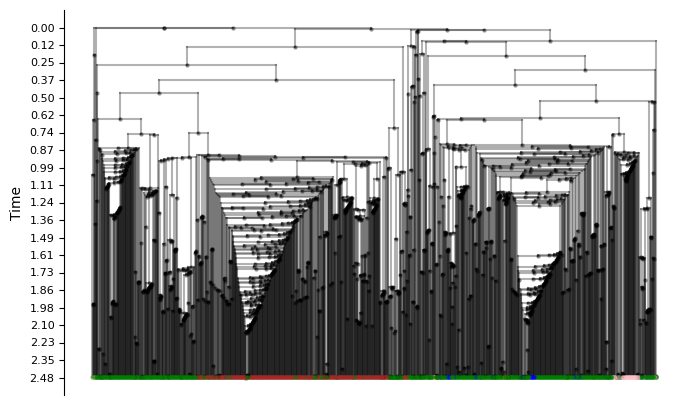

In [26]:
from plotters import draw_ultrametric_tree

draw_ultrametric_tree(DG, root=0 , add_labels=False)

In [27]:
import networkx as nx

def enforce_min_edge_length(G, root, min_length):
    """
    Adjust node times so that every edge satisfies

        T[parent] - T[child] >= min_length

    Leaves are kept fixed.
    Internal nodes are moved upward only when necessary.

    Updates:
        node['T']
        edge['length']

    Parameters
    ----------
    G : nx.DiGraph
        Rooted tree with parent -> child edges.
    root : node
        Root node.
    min_length : float
        Minimum allowed edge length.

    Returns
    -------
    nx.DiGraph
        Modified copy of G.
    """

    H = G.copy()

    # Postorder = children before parent
    for u in nx.dfs_postorder_nodes(H, root):

        children = list(H.successors(u))

        # leaf: fixed
        if not children:
            continue

        required_time = max(
            H.nodes[v]["T"] + min_length
            for v in children
        )

        # move parent upward only if necessary
        if H.nodes[u]["T"] < required_time:
            H.nodes[u]["T"] = required_time

    # recompute edge lengths
    for u, v in H.edges():
        H.edges[u, v]["length"] = (
            H.nodes[u]["T"] - H.nodes[v]["T"]
        )

    return H

In [28]:
df = pd.read_csv("../data/laml/LL_dict.csv", index_col=0)
df

,v,state_0,state_1,state_2,state_3,state_4
u,,,,,,
8,14,-1.113965,-inf,-2.072276,-1.653954,-3.317805
32,50,-6.594526,-inf,-7.967722,-7.024863,-9.354879
32,51,-0.794907,-inf,-2.154489,-1.225245,-3.537688
22,32,-7.018509,-inf,-8.459194,-3.544582,-11.381203
22,33,-0.796176,-inf,-2.149502,-1.227273,-3.531170
...,...,...,...,...,...,...
13,21,498.415741,-inf,493.427128,504.538981,490.511463
7,13,489.836932,-inf,483.576873,495.976923,481.932535
3,7,812.739815,-inf,806.457904,818.880011,804.833852


In [29]:
state_cols = [c for c in df.columns if c.startswith("state_")]

df["best_state"] = df[state_cols].idxmax(axis=1)
df

,v,state_0,state_1,state_2,state_3,state_4,best_state
u,,,,,,,
8,14,-1.113965,-inf,-2.072276,-1.653954,-3.317805,state_0
32,50,-6.594526,-inf,-7.967722,-7.024863,-9.354879,state_0
32,51,-0.794907,-inf,-2.154489,-1.225245,-3.537688,state_0
22,32,-7.018509,-inf,-8.459194,-3.544582,-11.381203,state_3
22,33,-0.796176,-inf,-2.149502,-1.227273,-3.531170,state_0
...,...,...,...,...,...,...,...
13,21,498.415741,-inf,493.427128,504.538981,490.511463,state_3
7,13,489.836932,-inf,483.576873,495.976923,481.932535,state_3
3,7,812.739815,-inf,806.457904,818.880011,804.833852,state_3


In [30]:
for u, row in df.iterrows():
    best_state = row["best_state"]
    v = row["v"]
    print(u, v, int(best_state[6:]))

8 14 0
32 50 0
32 51 0
22 32 3
22 33 0
15 22 3
15 23 1
8 15 0
4 8 0
4 9 0
2 4 0
2 5 0
1 2 0
10 16 0
10 17 0
6 10 0
6 11 0
3 6 0
52 80 0
52 81 0
34 52 0
34 53 0
24 34 0
24 35 0
18 24 0
54 82 0
228 286 0
287 344 0
287 345 0
228 287 3
180 228 0
288 346 0
288 347 0
229 288 0
229 289 0
180 229 3
142 180 3
480 562 0
480 563 0
410 480 0
754 812 0
754 813 0
696 754 0
696 755 0
632 696 3
1020 1068 0
1252 1284 0
1252 1285 0
1188 1252 0
1430 1464 0
1550 1578 0
1698 1720 0
1854 1870 0
1886 1900 0
1886 1901 0
1871 1886 0
2080 2102 0
2080 2103 0
2062 2080 3
2062 2081 0
2048 2062 3
2048 2063 0
2028 2048 3
2028 2049 0
2010 2028 3
2010 2029 0
1992 2010 3
1992 2011 0
1980 1992 3
1980 1993 0
1972 1980 3
1972 1981 0
1962 1972 3
2168 2184 0
2168 2185 0
2156 2168 0
2186 2200 0
2201 2222 0
2223 2244 0
2223 2245 0
2201 2223 0
2186 2201 3
2169 2186 0
2312 2324 0
2312 2325 0
2298 2312 3
2298 2313 0
2286 2298 3
2286 2299 0
2274 2286 3
2274 2287 0
2262 2274 3
2262 2275 0
2246 2262 0
2246 2263 0
2224 2246 3
2224 2

In [31]:
DG.nodes(data=True)

NodeDataView({1: {}, 2: {}, 3: {}, 4: {}, 5: {'state': 0}, 6: {}, 7: {}, 8: {}, 9: {'state': 0}, 10: {}, 11: {'state': 0}, 12: {}, 13: {}, 14: {'state': 0}, 15: {}, 16: {'state': 0}, 17: {'state': 0}, 18: {}, 19: {}, 20: {}, 21: {}, 22: {}, 23: {'state': 1}, 24: {}, 25: {}, 26: {}, 27: {}, 28: {}, 29: {}, 30: {}, 31: {}, 32: {}, 33: {'state': 0}, 34: {}, 35: {'state': 0}, 36: {}, 37: {}, 38: {}, 39: {}, 40: {}, 41: {}, 42: {}, 43: {}, 44: {}, 45: {'state': 0}, 46: {}, 47: {}, 48: {}, 49: {}, 50: {'state': 3}, 51: {'state': 0}, 52: {}, 53: {'state': 0}, 54: {}, 55: {}, 56: {}, 57: {}, 58: {'state': 0}, 59: {'state': 0}, 60: {}, 61: {}, 62: {'state': 4}, 63: {}, 64: {'state': 4}, 65: {'state': 0}, 66: {}, 67: {'state': 4}, 68: {'state': 0}, 69: {'state': 0}, 70: {}, 71: {}, 72: {}, 73: {'state': 0}, 74: {'state': 0}, 75: {'state': 0}, 76: {}, 77: {}, 78: {}, 79: {'state': 0}, 80: {'state': 0}, 81: {'state': 0}, 82: {'state': 0}, 83: {}, 84: {}, 85: {}, 86: {}, 87: {}, 88: {}, 89: {'state

In [32]:
from likelihood import add_node_times

DG = add_node_times(DG, root=0)


In [33]:
leaves = [n for n, d in DG.out_degree() if d == 0]

distances = {}
for leaf in leaves:
    distances[leaf] = nx.shortest_path_length(DG, source=0, target=leaf, weight='length')

min_dist = min(distances.values())
max_dist = max(distances.values())
print(min_dist, max_dist)

2.4760274804675464 2.476223176695044


In [34]:
for u, v, d in DG.edges(data=True):
    DG.edges[u, v]['length'] = DG.edges[u, v]['length'] / max_dist

In [35]:
leaves = [n for n, d in DG.out_degree() if d == 0]

distances = {}
for leaf in leaves:
    distances[leaf] = nx.shortest_path_length(DG, source=0, target=leaf, weight='length')

min_dist = min(distances.values())
max_dist = max(distances.values())
print(min_dist, max_dist)

0.9999209698748724 0.9999999999999993


In [36]:
for leaf in leaves:
    distance = nx.shortest_path_length(DG, source=0, target=leaf, weight="length")
    if distance < 1.0:
        parent = next(DG.predecessors(leaf))
        edge_length = DG[parent][leaf]["length"]
        excess = 1.0 - distance
        DG[parent][leaf]["length"] = edge_length + excess

In [37]:
distances = {}
for leaf in leaves:
    distances[leaf] = nx.shortest_path_length(DG, source=0, target=leaf, weight='length')

min_dist = min(distances.values())
max_dist = max(distances.values())
print(min_dist, max_dist)

1.0 1.0


In [38]:
DG = add_node_times(DG, root=0)

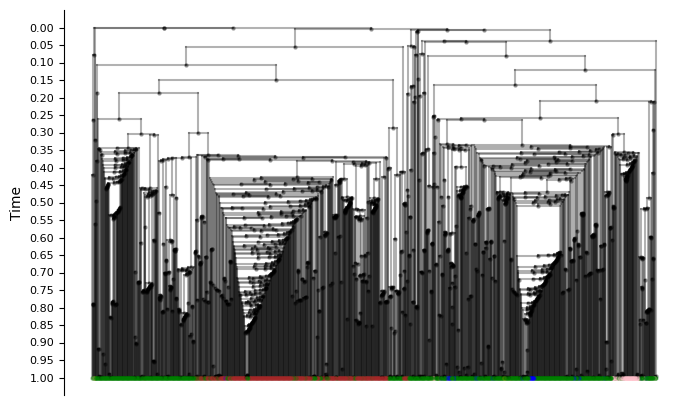

In [39]:
draw_ultrametric_tree(DG, root=0 , add_labels=False)

In [40]:
DG = enforce_min_edge_length(DG, root=0, min_length=0.001)

In [41]:
leaves = [n for n, d in DG.out_degree() if d == 0]

distances = {}
for leaf in leaves:
    distances[leaf] = nx.shortest_path_length(DG, source=0, target=leaf, weight='length')

min_dist = min(distances.values())
max_dist = max(distances.values())
print(min_dist, max_dist)

1.000999596159179 1.000999596159179


In [42]:
for u, v, d in DG.edges(data=True):
    DG.edges[u, v]['length'] = DG.edges[u, v]['length'] / (max_dist + 1e-9)

In [43]:
for leaf in leaves:
    distance = nx.shortest_path_length(DG, source=0, target=leaf, weight="length")
    if distance < 1.0:
        parent = next(DG.predecessors(leaf))
        edge_length = DG[parent][leaf]["length"]
        excess = 1.0 - distance
        DG[parent][leaf]["length"] = edge_length + excess

In [44]:
DG = add_node_times(DG, root=0)

In [45]:
leaves = [n for n, d in DG.out_degree() if d == 0]

distances = {}
for leaf in leaves:
    distances[leaf] = nx.shortest_path_length(DG, source=0, target=leaf, weight='length')

min_dist = min(distances.values())
max_dist = max(distances.values())
print(min_dist, max_dist)

1.0 1.0


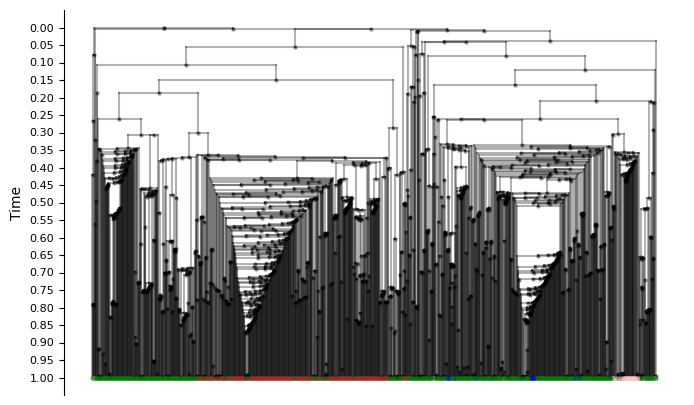

In [46]:
draw_ultrametric_tree(DG, root=0 , add_labels=False)

In [47]:
# leaves = [n for n, d in DG.out_degree() if d == 0]

# distances = {}
# for leaf in leaves:
#     distances[leaf] = nx.shortest_path_length(DG, source=0, target=leaf, weight='length')

# min_dist = min(distances.values())
# max_dist = max(distances.values())
# print(min_dist, max_dist)

In [48]:
for n in DG.nodes():
    if n in leaves:
        DG.nodes[n]['is_leaf'] = True
    else:
        DG.nodes[n]['is_leaf'] = False

In [49]:
from dataprocessor import export_tree

export_tree(DG, f"../data/KPTracer-Data/processed_data/nodes_0.csv", f"../data/KPTracer-Data/processed_data/edges_0.csv")

In [50]:
df = pd.read_csv("../data/KPTracer-Data/processed_data/0-T-0.refined.tree", sep="\t", header=None)
df

,0,1,2
0,1,2,-1
1,1,3,-1
2,2,4,-1
3,2,5,-1
4,3,6,-1
...,...,...,...
2916,2916,2918,-1
2917,2916,2919,-1
2918,2918,2920,10
2919,2918,2921,-1


In [51]:
df_nodes = pd.read_csv("../data/KPTracer-Data/processed_data/nodes_0.csv")
df_nodes

,node_id,T,is_leaf,state_id
0,1,0.999001,0,-1
1,2,0.921093,0,-1
2,3,0.996984,0,-1
3,4,0.733593,0,-1
4,5,0.000000,1,0
...,...,...,...,...
2917,2918,0.002017,0,-1
2918,2919,0.000000,1,0
2919,2920,0.000000,1,4
2920,2921,0.000000,1,0


In [52]:
df_merged = pd.merge(df, df_nodes, left_on=0, right_on='node_id')
df_merged.rename(columns={'T': 'T_0'}, inplace=True)
df_merged = pd.merge(df_merged, df_nodes, left_on=1, right_on='node_id')
df_merged = df_merged.rename(columns={'T': 'T_1'})
df_merged

,0,1,2,node_id_x,T_0,is_leaf_x,state_id_x,node_id_y,T_1,is_leaf_y,state_id_y
0,1,2,-1,1,0.999001,0,-1,2,0.921093,0,-1
1,1,3,-1,1,0.999001,0,-1,3,0.996984,0,-1
2,2,4,-1,2,0.921093,0,-1,4,0.733593,0,-1
3,2,5,-1,2,0.921093,0,-1,5,0.000000,1,0
4,3,6,-1,3,0.996984,0,-1,6,0.679116,0,-1
...,...,...,...,...,...,...,...,...,...,...,...
2916,2916,2918,-1,2916,0.004034,0,-1,2918,0.002017,0,-1
2917,2916,2919,-1,2916,0.004034,0,-1,2919,0.000000,1,0
2918,2918,2920,10,2918,0.002017,0,-1,2920,0.000000,1,4
2919,2918,2921,-1,2918,0.002017,0,-1,2921,0.000000,1,0


In [53]:
df_filt = df_merged[df_merged[2] != -1]
df_filt

,0,1,2,node_id_x,T_0,is_leaf_x,state_id_x,node_id_y,T_1,is_leaf_y,state_id_y
21,15,23,6,15,0.210402,0,-1,23,0.000000,1,1
38,27,40,2,27,0.497586,0,-1,40,0.495568,0,-1
40,28,42,2,28,0.809274,0,-1,42,0.534872,0,-1
48,32,50,1,32,0.206366,0,-1,50,0.000000,1,3
62,41,64,2,41,0.416612,0,-1,64,0.000000,1,4
...,...,...,...,...,...,...,...,...,...,...,...
2684,2682,2686,0,2682,0.205438,0,-1,2686,0.203421,0,-1
2701,2698,2703,7,2698,0.002074,0,-1,2703,0.000000,1,0
2734,2732,2736,7,2732,0.181228,0,-1,2736,0.166918,0,-1
2911,2909,2913,9,2909,0.127505,0,-1,2913,0.008070,0,-1


In [54]:
df_location = pd.read_csv('../data/KPTracer-Data/processed_data/0-T-0.location.labeling', sep='\t', header=None)
df_location.rename(columns={0: 'node_id', 1: 'state'}, inplace=True)
df_location

,node_id,state
0,1,0
1,2,0
2,3,0
3,4,0
4,5,0
...,...,...
2917,2918,0
2918,2919,0
2919,2920,4
2920,2921,0


In [55]:
df_merged = pd.merge(df_filt[[0, 1, 2, 'T_0', 'T_1']], df_location, left_on=0, right_on='node_id')
df_merged.rename(columns={'state': 'state_0'}, inplace=True)
df_merged = pd.merge(df_merged[[0, 1, 2, 'T_0', 'T_1', 'state_0']], df_location, left_on=1, right_on='node_id')
df_merged.rename(columns={'state': 'state_1'}, inplace=True)
df_merged

,0,1,2,T_0,T_1,state_0,node_id,state_1
0,15,23,6,0.210402,0.000000,0,23,1
1,27,40,2,0.497586,0.495568,0,40,4
2,28,42,2,0.809274,0.534872,0,42,4
3,32,50,1,0.206366,0.000000,0,50,3
4,41,64,2,0.416612,0.000000,0,64,4
...,...,...,...,...,...,...,...,...
94,2682,2686,0,0.205438,0.203421,0,2686,2
95,2698,2703,7,0.002074,0.000000,2,2703,0
96,2732,2736,7,0.181228,0.166918,2,2736,0
97,2909,2913,9,0.127505,0.008070,4,2913,0


In [56]:

transition_times_of_edges = []

for data in df_merged.itertuples():
    transition_times_of_edges.append(( data[0], data[1], data.state_0, data.state_1, (data.T_0 + data.T_1) / 2 ))

In [57]:
transition_times_of_edges

[(0, 15, 0, 1, 0.1052009315745481),
 (1, 27, 0, 4, 0.49657681644110707),
 (2, 28, 0, 4, 0.6720729884231382),
 (3, 32, 0, 3, 0.1031828989617911),
 (4, 41, 0, 4, 0.2083058460054788),
 (5, 55, 0, 4, 0.6669157929901375),
 (6, 84, 0, 4, 0.49501589025676945),
 (7, 94, 4, 0, 0.2457657207221011),
 (8, 151, 4, 0, 0.1122320841036079),
 (9, 176, 0, 3, 0.3249078016800956),
 (10, 177, 0, 1, 0.2736867237488344),
 (11, 244, 4, 0, 0.00104990576626325),
 (12, 248, 4, 0, 0.0010496850356637),
 (13, 282, 0, 3, 0.6913195602914376),
 (14, 283, 0, 3, 0.34344550601378565),
 (15, 314, 4, 0, 0.00104912637174175),
 (16, 343, 0, 3, 0.3925762668598572),
 (17, 377, 4, 0, 0.11104318357056875),
 (18, 398, 0, 1, 0.19189596500520825),
 (19, 404, 0, 3, 0.5908724211945245),
 (20, 405, 0, 3, 0.6431726692240145),
 (21, 408, 0, 3, 0.3529420000353405),
 (22, 444, 4, 0, 0.1215048786173266),
 (23, 470, 0, 3, 0.1957294493032696),
 (24, 514, 4, 0, 0.1624964773111857),
 (25, 535, 0, 3, 0.1898778338904295),
 (26, 592, 4, 0, 0.0010

In [58]:
node_colors = [(row.node_id, row.state) for row in df_location.itertuples()]
node_colors

[(1, 0),
 (2, 0),
 (3, 0),
 (4, 0),
 (5, 0),
 (6, 0),
 (7, 0),
 (8, 0),
 (9, 0),
 (10, 0),
 (11, 0),
 (12, 0),
 (13, 0),
 (14, 0),
 (15, 0),
 (16, 0),
 (17, 0),
 (18, 0),
 (19, 0),
 (20, 0),
 (21, 0),
 (22, 0),
 (23, 1),
 (24, 0),
 (25, 0),
 (26, 0),
 (27, 0),
 (28, 0),
 (29, 0),
 (30, 0),
 (31, 0),
 (32, 0),
 (33, 0),
 (34, 0),
 (35, 0),
 (36, 0),
 (37, 0),
 (38, 0),
 (39, 0),
 (40, 4),
 (41, 0),
 (42, 4),
 (43, 0),
 (44, 0),
 (45, 0),
 (46, 0),
 (47, 0),
 (48, 0),
 (49, 0),
 (50, 3),
 (51, 0),
 (52, 0),
 (53, 0),
 (54, 0),
 (55, 0),
 (56, 0),
 (57, 0),
 (58, 0),
 (59, 0),
 (60, 0),
 (61, 0),
 (62, 4),
 (63, 4),
 (64, 4),
 (65, 0),
 (66, 4),
 (67, 4),
 (68, 0),
 (69, 0),
 (70, 0),
 (71, 0),
 (72, 0),
 (73, 0),
 (74, 0),
 (75, 0),
 (76, 0),
 (77, 0),
 (78, 0),
 (79, 0),
 (80, 0),
 (81, 0),
 (82, 0),
 (83, 0),
 (84, 0),
 (85, 4),
 (86, 0),
 (87, 0),
 (88, 0),
 (89, 0),
 (90, 0),
 (91, 0),
 (92, 0),
 (93, 0),
 (94, 4),
 (95, 4),
 (96, 4),
 (97, 4),
 (98, 0),
 (99, 0),
 (100, 0),
 (101, 0

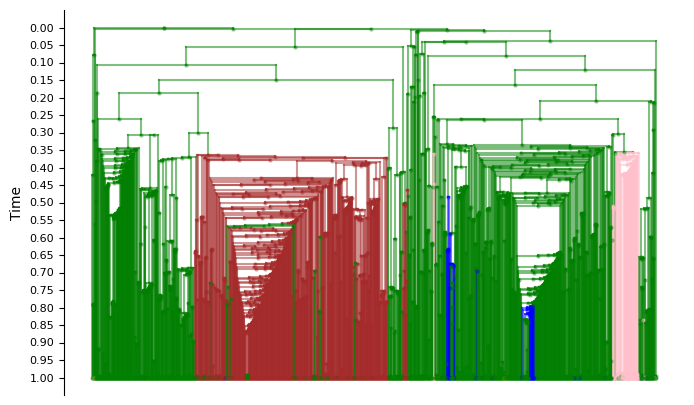

In [59]:
from plotters import draw_ultrametric_tree

draw_ultrametric_tree(DG, root=0 , add_labels=False, node_colors=node_colors, transition_times_of_edges=transition_times_of_edges)

In [60]:
for n, c in node_colors:
    DG.nodes[n]['state'] = c

In [61]:
export_tree(DG, f"../data/KPTracer-Data/processed_data/nodes_0.csv", f"../data/KPTracer-Data/processed_data/edges_0.csv")

In [62]:
with open('../data/KPTracer-Data/processed_data/transitions_0.csv', 'w') as f:
    print("parent,child,s0,s1,t", file=f)
    for u, v, s0, s1, t in transition_times_of_edges:
        f.write(f"{u},{v},{s0},{s1},{t}\n")

In [66]:
df_merged

,0,1,2,T_0,T_1,state_0,node_id,state_1
0,15,23,6,0.210402,0.000000,0,23,1
1,27,40,2,0.497586,0.495568,0,40,4
2,28,42,2,0.809274,0.534872,0,42,4
3,32,50,1,0.206366,0.000000,0,50,3
4,41,64,2,0.416612,0.000000,0,64,4
...,...,...,...,...,...,...,...,...
94,2682,2686,0,0.205438,0.203421,0,2686,2
95,2698,2703,7,0.002074,0.000000,2,2703,0
96,2732,2736,7,0.181228,0.166918,2,2736,0
97,2909,2913,9,0.127505,0.008070,4,2913,0


In [71]:
events = []

for u, v, t0, t1 in df_merged[[0, 1, 'T_0', 'T_1']].itertuples(index=False):
    events.append((t0, 'start', u, v))
    events.append((t1, 'end', u, v))

events.sort(reverse=True)
events

[(0.8092741153137966, 'start', 28, 42),
 (0.7851525337197144, 'start', 343, 409),
 (0.7432409920701102, 'start', 282, 337),
 (0.705884000070681, 'start', 408, 479),
 (0.6974732659677868, 'start', 55, 85),
 (0.6929785858946422, 'start', 404, 471),
 (0.6868910120275713, 'start', 283, 339),
 (0.6523716690896763, 'start', 904, 964),
 (0.6498156033601912, 'start', 176, 222),
 (0.6441812630882909, 'start', 405, 473),
 (0.642164075359738, 'end', 405, 473),
 (0.6408299049606611, 'start', 1112, 1174),
 (0.639398128512765, 'end', 282, 337),
 (0.636358320012488, 'end', 55, 85),
 (0.6293835876082129, 'start', 84, 113),
 (0.6206528720278106, 'start', 1518, 1545),
 (0.5795690962142608, 'start', 1748, 1762),
 (0.5632190555177397, 'start', 888, 944),
 (0.5473734474976688, 'start', 177, 225),
 (0.53487186153248, 'end', 28, 42),
 (0.5289268641323401, 'start', 1580, 1605),
 (0.5266530283333548, 'start', 2023, 2041),
 (0.5248924886752344, 'start', 1627, 1655),
 (0.5157872247720181, 'end', 904, 964),
 (0.5

In [89]:
groups = []
selected = set()
group_number = 0

edges_in_current_group = []

for event in events:
    t, event_type, u, v  = event
            
    if event_type == 'start':
        edges_in_current_group.append((u, v))
    elif event_type == 'end':
        if (u, v) not in selected:
            groups.append(edges_in_current_group.copy())
            for edge in edges_in_current_group:
                selected.add(edge)
            edges_in_current_group = []


for i, group in enumerate(groups):
    t0s = []
    t1s = []
    for u, v in group:
        edge = df_merged.loc[(df_merged[0] == u) & (df_merged[1] == v)]
        t0 = edge['T_0'].values[0]
        t1 = edge['T_1'].values[0]
        t0s.append(t0)
        t1s.append(t1)
    min_t0 = min(t0s) if t0s else None
    max_t1 = max(t1s) if t1s else None
    print(f"Min T_0: {min_t0}, Max T_1: {max_t1}")

    for (u, v) in group:
        df_merged.loc[(df_merged[0] == u) & (df_merged[1] == v), 'group_transition_time'] = (9 * min_t0 + max_t1) / 10
        df_merged.loc[(df_merged[0] == u) & (df_merged[1] == v), 'group'] = i


df_merged

Min T_0: 0.6441812630882909, Max T_1: 0.642164075359738
Min T_0: 0.4966518604754937, Max T_1: 0.4955676047236129
Min T_0: 0.4401706040760136, Max T_1: 0.4381534163474607
Min T_0: 0.4300827202693937, Max T_1: 0.4280674777046964
Min T_0: 0.4120362010868454, Max T_1: 0.4101417940288026
Min T_0: 0.3196008925066631, Max T_1: 0.3175837047781102
Min T_0: 0.3049563869546718, Max T_1: 0.3029366909835939
Min T_0: 0.2054381798541933, Max T_1: 0.2034209921256404
Min T_0: 0.1791311282640477, Max T_1: 0.1669184194570477
Min T_0: 0.0094659200879237, Max T_1: 0.0080696145284111
Min T_0: 0.0020171935224131, Max T_1: 0.0


,0,1,2,T_0,T_1,state_0,node_id,state_1,group_transition_time,group
0,15,23,6,0.210402,0.000000,0,23,1,0.205236,7.0
1,27,40,2,0.497586,0.495568,0,40,4,0.496543,1.0
2,28,42,2,0.809274,0.534872,0,42,4,0.643980,0.0
3,32,50,1,0.206366,0.000000,0,50,3,0.205236,7.0
4,41,64,2,0.416612,0.000000,0,64,4,0.411847,4.0
...,...,...,...,...,...,...,...,...,...,...
94,2682,2686,0,0.205438,0.203421,0,2686,2,0.205236,7.0
95,2698,2703,7,0.002074,0.000000,2,2703,0,0.001815,10.0
96,2732,2736,7,0.181228,0.166918,2,2736,0,0.177910,8.0
97,2909,2913,9,0.127505,0.008070,4,2913,0,0.009326,9.0


In [91]:
with open("../data/KPTracer-Data/processed_data/transitions_0_adjusted.csv", "w") as f:
    print("parent,child,s0,s1,t", file=f)
    for parent, child, state_0, state_1, transition_time in df_merged[[0, 1, 'state_0', 'state_1', 'group_transition_time']].itertuples(index=False):
        f.write(f"{parent},{child},{state_0},{state_1},{transition_time}\n")

In [93]:
first_transition_times = (
    df_merged.groupby("group", sort=False)["group_transition_time"]
      .first()
)

with open("../data/KPTracer-Data/processed_data/transition-times.txt", "w") as f:
    for time in sorted(first_transition_times):
        f.write(f"{time}\n")

print(first_transition_times)

group
7.0     0.205236
1.0     0.496543
0.0     0.643980
4.0     0.411847
2.0     0.439969
10.0    0.001815
5.0     0.319399
8.0     0.177910
9.0     0.009326
6.0     0.304754
3.0     0.429881
Name: group_transition_time, dtype: float64


In [63]:
transition_edges = df_merged[df_merged["state_0"] != df_merged["state_1"]].copy()
transition_edges["interval_start"] = transition_edges[["T_0", "T_1"]].min(axis=1)
transition_edges["interval_end"] = transition_edges[["T_0", "T_1"]].max(axis=1)

minimum_transition_times = []
transition_groups = []

for (state_0, state_1), state_edges in transition_edges.groupby(["state_0", "state_1"], sort=False):
    overlap_group = []
    shared_start = None
    shared_end = None

    for _, edge in state_edges.sort_values("interval_end").iterrows():
        if overlap_group:
            next_start = max(shared_start, edge.interval_start)
            next_end = min(shared_end, edge.interval_end)
        else:
            next_start = edge.interval_start
            next_end = edge.interval_end

        if overlap_group and next_start < next_end:
            overlap_group.append(edge)
            shared_start = next_start
            shared_end = next_end
        else:
            if overlap_group:
                minimum_transition_times.append(shared_start)
                group_edge_indices = [group_edge.name for group_edge in overlap_group]
                transition_groups.append((state_0, state_1, shared_start, shared_end, group_edge_indices))

            overlap_group = [edge]
            shared_start = edge.interval_start
            shared_end = edge.interval_end

    if overlap_group:
        minimum_transition_times.append(shared_start)
        group_edge_indices = [group_edge.name for group_edge in overlap_group]
        transition_groups.append((state_0, state_1, shared_start, shared_end, group_edge_indices))

minimum_transition_times

[np.float64(0.0),
 np.float64(0.0),
 np.float64(0.4280674777046964),
 np.float64(0.4955676047236129),
 np.float64(0.636358320012488),
 np.float64(0.1653309234769914),
 np.float64(0.642164075359738),
 np.float64(0.0),
 np.float64(0.0080696145284111),
 np.float64(0.3029366909835939),
 np.float64(0.4381534163474607),
 np.float64(0.0),
 np.float64(0.2034209921256404),
 np.float64(0.4101417940288026),
 np.float64(0.5157872247720181),
 np.float64(0.0),
 np.float64(0.0046883204465123),
 np.float64(0.0),
 np.float64(0.1669184194570477),
 np.float64(0.3175837047781102),
 np.float64(0.0)]

In [64]:
sorted(minimum_transition_times)

[np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0046883204465123),
 np.float64(0.0080696145284111),
 np.float64(0.1653309234769914),
 np.float64(0.1669184194570477),
 np.float64(0.2034209921256404),
 np.float64(0.3029366909835939),
 np.float64(0.3175837047781102),
 np.float64(0.4101417940288026),
 np.float64(0.4280674777046964),
 np.float64(0.4381534163474607),
 np.float64(0.4955676047236129),
 np.float64(0.5157872247720181),
 np.float64(0.636358320012488),
 np.float64(0.642164075359738)]

In [65]:
with open("../data/KPTracer-Data/processed_data/transition-times.txt", "w") as f:
    for time in sorted(minimum_transition_times):
        f.write(f"{time}\n")

In [66]:
min_edge_length = 0.001
transition_time_by_edge = {}

for group_state_0, group_state_1, group_start, _, group_edge_indices in transition_groups:
    group_transition_time = (
        min_edge_length / 2 if group_start == 0 else group_start
    )
    for edge_index in group_edge_indices:
        transition_time_by_edge[edge_index] = group_transition_time

adjusted_transition_times = []
for edge_index, parent, state_0, state_1, _ in transition_times_of_edges:
    if edge_index in transition_time_by_edge:
        adjusted_transition_times.append(
            (
                edge_index,
                parent,
                state_0,
                state_1,
                transition_time_by_edge[edge_index],
            )
        )

with open("../data/KPTracer-Data/processed_data/transitions_0_adjusted.csv", "w") as f:
    print("parent,child,s0,s1,t", file=f)
    for parent, child, state_0, state_1, transition_time in adjusted_transition_times:
        f.write(f"{parent},{child},{state_0},{state_1},{transition_time}\n")

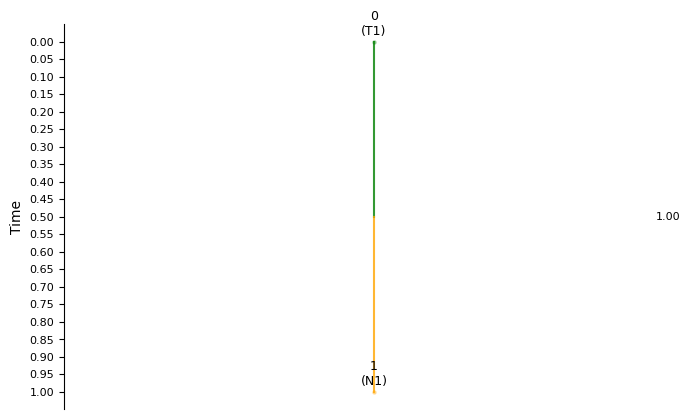

In [587]:
import networkx as nx
from plotters import draw_ultrametric_tree

example_tree = nx.DiGraph()
example_tree.add_node(0, T=1.0)
example_tree.add_node(1)
example_tree.add_edge(0, 1, length=1.0)

example_node_colors = [(0, "T1"), (1, "N1")]
example_transitions = [(0, 1, "T1", "N1", 0.5)]

draw_ultrametric_tree(
    example_tree,
    root=0,
    add_labels=True,
    node_colors=example_node_colors,
    transition_times_of_edges=example_transitions,
)